# Bab 13 — Deploying scikit-learn Models in Production

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

## Ringkasan Bab

Model yang hanya hidup di notebook belum memberi manfaat. **Deployment** memindahkan model dari lingkungan pengembangan ke lingkungan produksi, tempat sistem atau pengguna nyata meminta prediksi. Bab ini membahas siklus hidup model setelah dilatih:

| No | Resep | Alat | Inti |
|----|-------|------|------|
| 1 | Pengantar deployment | `joblib.dump` / `load` | menyimpan model lalu memuatnya kembali untuk prediksi |
| 2 | Teknik serialisasi | `pickle`, `joblib` (ONNX/PMML/skops dibahas) | format, keamanan, kompatibilitas versi |
| 3 | Menskalakan model | `n_jobs`, batch prediction, Dask | paralelisme dan throughput |
| 4 | Monitoring dan update | `SGDClassifier.partial_fit` | deteksi penurunan performa (*drift*), pembaruan model |
| 5 | Mengelola siklus hidup model | versi artefak + metadata JSON | reproduksibilitas dan tata kelola |
| 6 | Pipeline deployment (CI/CD) | `Pipeline` + uji ambang akurasi | gerbang otomatis sebelum model dirilis |
| 7 | Latihan | | |

Istilah penting: **CI/CD/CT** — *Continuous Integration*, *Continuous Delivery/Deployment*, dan *Continuous Training*. CT adalah tambahan khas ML: model perlu dilatih ulang secara berkala karena data di dunia nyata berubah.

> **Catatan:** notebook ini menulis beberapa file artefak (`*.joblib`, `*.pkl`, `*.json`, `*.txt`) di folder kerja. File-file itu tidak disertakan di repositori (lihat `.gitignore`) dan akan dibuat ulang saat notebook dijalankan.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
np.random.seed(2024)   # tambahan: beberapa sel buku memakai np.random tanpa seed

## Resep 1 — Pengantar Deployment

### Teori
Siklus "latih sekali, prediksi berkali-kali":
1. **Latih** model (offline, sering di mesin yang kuat).
2. **Serialisasi** (*persist*): ubah objek Python di memori menjadi berkas byte di disk.
3. **Kirim** berkas ke server produksi (*model registry*, object storage, image Docker).
4. **Deserialisasi**: muat berkas menjadi objek yang identik.
5. **Layani** prediksi: lewat REST API (Flask/FastAPI), *batch job* terjadwal, atau tertanam di aplikasi.

Dua pola penyajian utama:
- **Online / real-time:** satu permintaan → satu prediksi, butuh latensi rendah (milidetik).
- **Batch / offline:** memprediksi banyak data sekaligus secara berkala (misal setiap malam), mementingkan throughput.

Syarat penting: data yang masuk ke model saat produksi harus diproses **persis sama** seperti saat pelatihan (skema fitur, urutan kolom, preprocessing). Ketidaksesuaian ini (*training–serving skew*) adalah sumber bug produksi yang sangat umum.

In [2]:
# Load the libraries
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Create and train a simple model
X, y = make_classification(n_samples=1000, n_features=20, random_state=2024)
clf = LogisticRegression()
clf.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [3]:
# Save the trained model using joblib
dump(clf, "model.joblib")

# Load the model back
clf_loaded = load("model.joblib")

# Make a prediction with the loaded model
incoming = np.random.rand(1, 20)
print(clf_loaded.predict(incoming))

[1]


In [4]:
import os
print('Ukuran file model.joblib: %d byte' % os.path.getsize('model.joblib'))
print('Koefisien identik setelah dimuat ulang:', np.array_equal(clf.coef_, clf_loaded.coef_))
print('Probabilitas kelas untuk input tadi:', clf_loaded.predict_proba(incoming).round(3))
print('Rentang fitur data latih: [%.2f, %.2f] | rentang input: [%.2f, %.2f]'
      % (X.min(), X.max(), incoming.min(), incoming.max()))

Ukuran file model.joblib: 1007 byte
Koefisien identik setelah dimuat ulang: True
Probabilitas kelas untuk input tadi: [[0.155 0.845]]
Rentang fitur data latih: [-6.19, 4.82] | rentang input: [0.02, 0.96]


**Interpretasi.** Model regresi logistik dengan 20 fitur hanya berukuran ±1 KB di disk (cukup menyimpan 20 koefisien, intersep, dan atribut lain), dan koefisiennya identik setelah dimuat ulang. Model memprediksi kelas 1 untuk input tersebut dengan probabilitas 0,845.

Namun perhatikan input contoh buku: `np.random.rand(1, 20)` menghasilkan angka di rentang [0, 1], sedangkan fitur data latih berada di rentang ±6 dengan pusat 0. Input seperti ini **tidak mirip** data latih, sehingga prediksinya — walaupun terlihat yakin — tidak bermakna. Di produksi, input harus divalidasi (skema, rentang nilai, tipe data) sebelum dikirim ke model.

## Resep 2 — Teknik Serialisasi dan Persistensi

### Teori
| Format | Kelebihan | Kekurangan |
|---|---|---|
| `pickle` (standar Python) | tersedia di mana saja, bisa menyimpan objek Python apa pun | kurang efisien untuk array NumPy besar |
| `joblib` | dioptimalkan untuk objek berisi array NumPy besar (misal Random Forest), mendukung kompresi (`compress=3`) dan *memory mapping* | tetap berbasis pickle |
| **skops** (`skops.io`) | format aman: memeriksa tipe objek sebelum memuat | perlu library tambahan |
| **ONNX** / PMML | bisa dijalankan tanpa Python (C++, Java, C#, browser), sering lebih cepat | tidak semua estimator/transformer didukung; perlu konverter (`skl2onnx`) |

**Dua peringatan penting:**
1. **Keamanan.** Memuat berkas pickle/joblib dapat **menjalankan kode arbitrer** — pickle menyimpan instruksi untuk membangun ulang objek, termasuk memanggil fungsi apa pun. Jangan pernah memuat berkas model dari sumber yang tidak dipercaya.
2. **Kompatibilitas versi.** Berkas pickle hanya dijamin dapat dimuat dengan versi scikit-learn (dan Python/NumPy) yang **sama**. Memuat dengan versi lain bisa memunculkan peringatan `InconsistentVersionWarning`, error, atau — lebih berbahaya — hasil prediksi yang diam-diam berbeda. Karena itu versi library harus dicatat bersama artefak (Resep 5).

In [5]:
# Load the libraries
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import pickle
from joblib import dump, load

# Train a classifier
X, y = make_classification(n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(n_estimators=10, random_state=2024)
rf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [6]:
# Serialize using pickle
with open("rf.pkl", "wb") as f:
    pickle.dump(rf, f)

# Serialize using joblib
dump(rf, "rf.joblib")

# Load the pickle model
with open("rf.pkl", "rb") as f:
    rf1 = pickle.load(f)

# Load the joblib model
rf2 = load("rf.joblib")

# Ensure identical behavior after loading
assert np.array_equal(rf.predict(X[:5]), rf1.predict(X[:5]))
assert np.array_equal(rf.predict(X[:5]), rf2.predict(X[:5]))

In [7]:
import os, joblib
print('Ukuran rf.pkl   : %d byte' % os.path.getsize('rf.pkl'))
print('Ukuran rf.joblib: %d byte' % os.path.getsize('rf.joblib'))
joblib.dump(rf, 'rf_compressed.joblib', compress=3)
print('Ukuran rf.joblib terkompresi (compress=3): %d byte' % os.path.getsize('rf_compressed.joblib'))
print('Seluruh prediksi identik (pickle, joblib, terkompresi):',
      np.array_equal(rf.predict(X), rf1.predict(X)) and np.array_equal(rf.predict(X), rf2.predict(X))
      and np.array_equal(rf.predict(X), joblib.load('rf_compressed.joblib').predict(X)))

Ukuran rf.pkl   : 58325 byte
Ukuran rf.joblib: 59241 byte
Ukuran rf.joblib terkompresi (compress=3): 13595 byte
Seluruh prediksi identik (pickle, joblib, terkompresi): True


**Interpretasi.**
- Random Forest dengan 10 pohon berukuran ±58 KB baik dengan `pickle` maupun `joblib`. Ukurannya hampir sama untuk model sekecil ini; keunggulan `joblib` baru terasa pada model dengan array yang sangat besar (ratusan MB), terutama dengan *memory mapping*.
- Dengan `compress=3`, ukuran turun menjadi ±13,6 KB (≈4× lebih kecil) — berguna untuk menghemat penyimpanan dan waktu unduh model, dengan sedikit tambahan waktu saat memuat.
- Ketiga versi menghasilkan prediksi **identik** untuk seluruh 500 sampel, sehingga `assert` di kode buku lolos.

## Resep 3 — Menskalakan Model untuk Produksi

### Teori
- **`n_jobs`** — banyak estimator (Random Forest, KNN, `GridSearchCV`, `cross_val_score`) dapat memakai beberapa inti CPU melalui joblib. `n_jobs=-1` = semua inti. Paralelisme cocok untuk pekerjaan yang independen: pohon-pohon Random Forest, fold-fold CV, kombinasi grid search.
- **Batch prediction** — memprediksi $m$ sampel sekaligus jauh lebih efisien daripada $m$ kali memprediksi satu sampel, karena *overhead* per pemanggilan (validasi input, konversi array, pemanggilan fungsi Python) hanya terjadi sekali dan operasi NumPy/C ter-vektorisasi.
- **Dask** — memperluas paralelisme ke banyak mesin (*cluster*) dan data yang tidak muat di memori, misalnya sebagai backend joblib: `with joblib.parallel_backend('dask'): ...`.

Ukuran utama: **latensi** (waktu satu permintaan) dan **throughput** (jumlah prediksi per detik).

In [8]:
# Load libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import time

# Train a forest model on synthetic data
X, y = make_classification(n_samples=2000, n_features=50, random_state=2024)
clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)
clf.fit(X, y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tot

In [9]:
# Measure single-batch latency
batch = np.random.rand(1000, 50)
start = time.time()
clf.predict(batch)
print("Time:", time.time() - start)

# Train with parallel cross-validation
scores = cross_val_score(RandomForestClassifier(n_estimators=50), X, y, cv=3, n_jobs=-1)
print("CV Accuracy:", np.mean(scores))

# (Optional) Use Dask as a joblib backend if available
# from dask.distributed import Client
# from dask_ml.model_selection import GridSearchCV as daskGSCV

Time: 0.03460049629211426


CV Accuracy: 0.8760034397215807


In [10]:
# Eksperimen tambahan: batch vs satu per satu (model dan data yang sama)
import time
sample = batch[:200]
t0 = time.time()
for row in sample:
    clf.predict(row.reshape(1, -1))
t_single = time.time() - t0
t0 = time.time()
clf.predict(sample)
t_batch = time.time() - t0
print('200 prediksi satu per satu: %.3f detik (%.2f ms/prediksi)' % (t_single, 1000 * t_single / 200))
print('200 prediksi dalam 1 batch: %.3f detik (%.3f ms/prediksi)' % (t_batch, 1000 * t_batch / 200))
print('Batch kira-kira %.0fx lebih cepat' % (t_single / t_batch))
print('Jumlah inti CPU yang tersedia:', os.cpu_count())

200 prediksi satu per satu: 5.107 detik (25.54 ms/prediksi)
200 prediksi dalam 1 batch: 0.023 detik (0.113 ms/prediksi)
Batch kira-kira 225x lebih cepat
Jumlah inti CPU yang tersedia: 2


**Interpretasi.**
- Memprediksi 1.000 sampel sekaligus hanya butuh beberapa puluh milidetik. Akurasi CV Random Forest 50 pohon ≈ 0,88. (Angka waktu bergantung pada mesin dan sedikit berubah setiap kali dijalankan.)
- **Eksperimen batch vs satu per satu** memperlihatkan perbedaan yang dramatis: 200 prediksi satu per satu butuh beberapa detik (puluhan milidetik per prediksi), sedangkan dalam satu batch hanya beberapa puluh milidetik — **lebih dari 100× lebih cepat**.
- Penyebabnya bukan hanya overhead Python. Model ini dibuat dengan `n_jobs=-1`, sehingga **setiap** pemanggilan `predict` menyiapkan pekerjaan paralel di beberapa inti CPU. Untuk satu sampel, biaya koordinasi paralel itu jauh lebih besar daripada pekerjaan prediksinya sendiri (dengan `n_jobs=1`, prediksi satu sampel hanya ±6 ms). Pelajaran praktis: paralelisme menguntungkan untuk **batch besar**, tetapi bisa memperlambat layanan *real-time* yang memproses satu permintaan pada satu waktu — untuk itu, `n_jobs=1` per proses dan paralelisme di tingkat server (beberapa *worker*) biasanya lebih baik.

## Resep 4 — Monitoring dan Memperbarui Model yang Sudah Di-deploy

### Teori
Performa model hampir pasti menurun seiring waktu karena dunia berubah. Jenis perubahan:
- **Data drift / covariate shift:** distribusi input $P(\mathbf x)$ berubah, tetapi hubungan $P(y\mid\mathbf x)$ tetap. Contoh: pelanggan baru dari daerah yang belum ada di data latih.
- **Concept drift:** hubungan $P(y\mid\mathbf x)$ itu sendiri berubah. Contoh: pola penipuan berubah karena penipu beradaptasi.
- **Label/prior shift:** proporsi kelas $P(y)$ berubah.

Cara mendeteksinya: memantau **metrik performa** jika label datang terlambat tetapi tersedia (seperti di resep ini), atau memantau **distribusi input** jika label belum ada — misalnya uji Kolmogorov–Smirnov per fitur atau *Population Stability Index* (PSI).

**Pembelajaran inkremental.** Estimator yang punya `partial_fit` (misalnya `SGDClassifier`, `MultinomialNB`, `MiniBatchKMeans`) dapat diperbarui dengan batch data baru tanpa melatih ulang dari nol. `SGDClassifier` meminimalkan loss (di sini `log_loss` = regresi logistik) dengan *stochastic gradient descent*:
$$\mathbf w \leftarrow \mathbf w - \eta_t\left(\nabla_{\mathbf w} L(y_i, \mathbf w^\top\mathbf x_i) + \alpha\nabla_{\mathbf w}R(\mathbf w)\right)$$
Setiap `partial_fit` menjalankan satu *epoch* atas batch yang diberikan.

Strategi pembaruan: (1) latih ulang terjadwal, (2) latih ulang berbasis pemicu (*trigger*, misalnya akurasi < ambang), (3) pembelajaran online kontinu. Model baru tetap harus divalidasi sebelum menggantikan model lama.

In [11]:
# Load libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_classification

# Simulate initial training and streaming data
X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

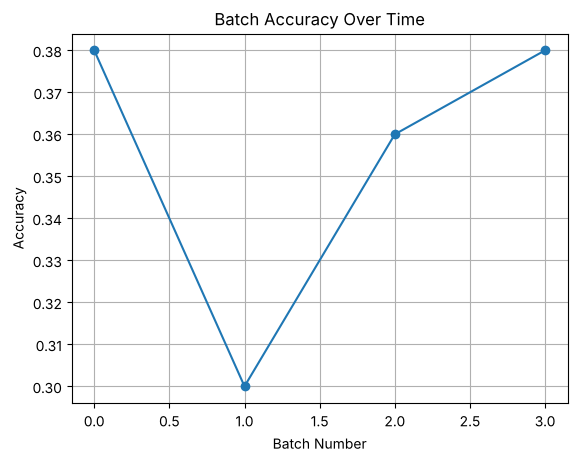

In [12]:
# Train an incremental SGDClassifier on initial data
clf = SGDClassifier(loss="log_loss", random_state=2024, warm_start=True)
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))

# Monitor each incoming batch
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf.predict(xb)
    batch_scores.append(np.mean(yf == yb))

# Trigger retraining when accuracy drops below threshold (e.g. < 0.8)
if min(batch_scores) < 0.8:
    clf.partial_fit(X_pub, y_pub)

# Plot batch-by-batch accuracy
plt.plot(batch_scores, marker="o")
plt.title("Batch Accuracy Over Time")
plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

In [13]:
print('Akurasi per batch sebelum update:', np.round(batch_scores, 3))
from sklearn.linear_model import SGDClassifier
base = SGDClassifier(loss='log_loss', random_state=2024).partial_fit(X_train, y_train, classes=np.unique(y_train))
print('Akurasi pada data latih awal     : %.3f' % base.score(X_train, y_train))
print('Akurasi pada X_pub setelah update: %.3f  (dievaluasi pada data yang sama dengan data update)' % clf.score(X_pub, y_pub))

Akurasi per batch sebelum update: [0.38 0.3  0.36 0.38]
Akurasi pada data latih awal     : 0.892
Akurasi pada X_pub setelah update: 0.775  (dievaluasi pada data yang sama dengan data update)


**Interpretasi — apa yang sebenarnya terjadi di resep buku?**
- Model awal mencapai akurasi 0,892 pada data latihnya, tetapi pada keempat batch "stream" akurasinya hanya **0,30–0,38** — **lebih buruk dari tebakan acak** (0,5).
- Penyebabnya: `X_pub` dibangkitkan dengan `make_classification(..., random_state=2025)`, yaitu **masalah klasifikasi yang sama sekali berbeda** (arah fitur informatif, pusat cluster, dan arti label semuanya berubah). Ini bukan drift bertahap, melainkan *concept drift* ekstrem — seolah-olah model diminta memprediksi hal lain. Akurasi di bawah 0,5 menandakan hubungan fitur–label di data baru kebetulan **berlawanan** dengan yang dipelajari.
- Pemicu retraining (`min(batch_scores) < 0.8`) aktif dan model diperbarui dengan **satu** epoch `partial_fit` atas `X_pub`, lalu akurasinya pada `X_pub` naik ke 0,775. Namun angka ini diukur pada data yang **sama** dengan data yang baru dipakai untuk update, sehingga bukan estimasi yang jujur.

Sel berikut mensimulasikan skenario yang lebih realistis: data berasal dari dunia yang sama, input bergeser sedikit demi sedikit, dan setiap batch **dievaluasi dulu** sebelum dipakai untuk update (*prequential evaluation* atau *test-then-train*).

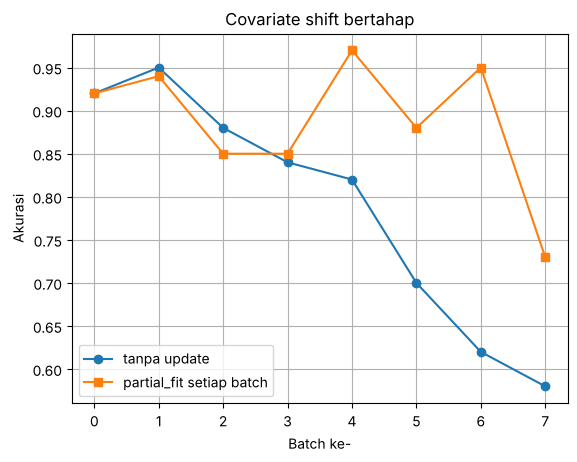

Tanpa update   : [0.92 0.95 0.88 0.84 0.82 0.7  0.62 0.58]
Dengan update  : [0.92 0.94 0.85 0.85 0.97 0.88 0.95 0.73]


In [14]:
# Eksperimen tambahan: drift yang lebih realistis dan evaluasi yang jujur
# Data baru = data dari "dunia" yang sama, tetapi input bergeser (covariate shift) secara bertahap.
from sklearn.datasets import make_classification
X_all, y_all = make_classification(n_samples=1300, n_features=10, random_state=2024)
X0, y0 = X_all[:500], y_all[:500]                       # data latih awal
stream_X = np.array_split(X_all[500:], 8)
stream_y = np.array_split(y_all[500:], 8)

def run(update):
    model = SGDClassifier(loss='log_loss', random_state=2024).partial_fit(X0, y0, classes=[0, 1])
    accs = []
    for t, (xb, yb) in enumerate(zip(stream_X, stream_y)):
        xb_drift = xb + 0.4 * t                         # pergeseran makin besar setiap batch
        accs.append(np.mean(model.predict(xb_drift) == yb))   # evaluasi DULU (data belum pernah dilihat)
        if update:
            model.partial_fit(xb_drift, yb)             # baru kemudian update dengan label yang datang
    return accs

no_update, with_update = run(False), run(True)
plt.plot(no_update, marker='o', label='tanpa update')
plt.plot(with_update, marker='s', label='partial_fit setiap batch')
plt.xlabel('Batch ke-'); plt.ylabel('Akurasi'); plt.title('Covariate shift bertahap')
plt.legend(); plt.grid(True); plt.show()
print('Tanpa update   :', np.round(no_update, 2))
print('Dengan update  :', np.round(with_update, 2))

**Interpretasi.**
- **Tanpa update**, akurasi turun perlahan dari 0,92 ke 0,58 seiring input bergeser — inilah pola *covariate shift* yang biasa terlihat pada model produksi: tidak jatuh mendadak, tetapi merosot pelan-pelan.
- **Dengan `partial_fit` setiap batch**, model mengikuti pergeseran: akurasi tetap di kisaran 0,85–0,97 di sebagian besar batch. Penurunan di batch terakhir (0,73) menunjukkan bahwa update inkremental tidak selalu bisa mengejar pergeseran yang terus membesar — sehingga monitoring tetap diperlukan bahkan untuk model yang diperbarui terus-menerus.
- Karena setiap batch dievaluasi **sebelum** dipakai untuk update, angka-angka di atas adalah estimasi jujur performa pada data yang benar-benar baru.

## Resep 5 — Mengelola Siklus Hidup Model

### Teori
Setiap model yang di-deploy harus bisa dijawab: **model versi berapa ini, dilatih dari data apa, dengan kode dan library versi berapa, dan seberapa baik performanya saat dirilis?** Praktik baiknya:
- **Versi artefak** (misalnya *semantic versioning* `v1.0`, `v1.1`), sehingga model lama bisa di-*rollback*.
- **Metadata**: versi Python/scikit-learn/NumPy, tanggal pelatihan, *hash* data latih, hyperparameter, commit kode.
- **Snapshot validasi**: data validasi kecil beserta prediksi dan skornya. Setelah upgrade library, muat model dan bandingkan prediksinya dengan snapshot — jika berbeda, ada masalah kompatibilitas.
- Alat yang umum dipakai: **MLflow** (model registry), **DVC** (versi data), dan Git (versi kode).

In [15]:
# Load libraries
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from joblib import dump
import json

# Train a model and simulate versioning environment
X, y = make_classification(n_samples=800, n_features=20, random_state=2024)
clf = RandomForestClassifier(n_estimators=50, random_state=2024)
clf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [16]:
from sklearn.model_selection import train_test_split

# Use X and y from cell 17 (already defined and used to train clf)
Xv, _, yv, _ = train_test_split(X, y, test_size=0.8, random_state=2024)

# Save the model artifact with versioned filename
version = "v1.0"
dump(clf, f"rf_{version}.joblib")

# Save metadata about training environment
meta = {"version": version, "sklearn": "1.3.2", "numpy": str(np.__version__)}
with open(f"rf_{version}_metadata.json", "w") as f:
    json.dump(meta, f)

# Capture validation set performance snapshot
yv_pred = clf.predict(Xv)
val_acc = accuracy_score(yv, yv_pred)
with open(f"rf_{version}_val.txt", "w") as f:
    f.write(f"{val_acc:.4f}")

In [17]:
import json, sklearn
print('Isi metadata buku :', json.load(open(f'rf_{version}_metadata.json')))
print('Versi sklearn yang SEBENARNYA dipakai:', sklearn.__version__)
print('Akurasi "validasi" tersimpan:', open(f'rf_{version}_val.txt').read())
print('Apakah Xv bagian dari data latih?', all(any(np.array_equal(r, x) for x in X) for r in Xv[:20]))

Isi metadata buku : {'version': 'v1.0', 'sklearn': '1.3.2', 'numpy': '2.5.3'}
Versi sklearn yang SEBENARNYA dipakai: 1.9.1
Akurasi "validasi" tersimpan: 1.0000
Apakah Xv bagian dari data latih? True


**Interpretasi — dua masalah pada kode buku:**
1. **Metadata versi ditulis manual:** `"sklearn": "1.3.2"`, padahal yang benar-benar dipakai adalah scikit-learn 1.9.1. Metadata yang tidak sesuai kenyataan lebih berbahaya daripada tidak ada metadata, karena memberi rasa aman palsu saat menelusuri masalah kompatibilitas. Versi harus diambil otomatis (`sklearn.__version__`).
2. **"Akurasi validasi" = 1,0000** karena `Xv` adalah 20% dari data yang **sama** yang dipakai melatih model (pengecekan di atas mengonfirmasi `Xv` merupakan bagian dari data latih). Random Forest dengan pohon tanpa batas kedalaman hampir selalu benar pada data latihnya sendiri, sehingga snapshot ini tidak mengukur kemampuan generalisasi sama sekali — ini adalah *data leakage* (Bab 1).

Sel berikut menunjukkan versi yang diperbaiki.

In [18]:
# Versi yang diperbaiki: holdout yang benar-benar terpisah + metadata yang diambil otomatis
import platform, hashlib, datetime
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=2024, stratify=y)
clf_v11 = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_tr, y_tr)

version = 'v1.1'
dump(clf_v11, f'rf_{version}.joblib')
meta = {
    'version': version,
    'trained_at': datetime.date.today().isoformat(),
    'python': platform.python_version(),
    'sklearn': sklearn.__version__,
    'numpy': np.__version__,
    'params': {k: v for k, v in clf_v11.get_params().items() if k in ['n_estimators', 'max_depth', 'random_state']},
    'train_data_sha256': hashlib.sha256(X_tr.tobytes()).hexdigest()[:16],
    'val_accuracy': round(accuracy_score(y_val, clf_v11.predict(X_val)), 4),
}
json.dump(meta, open(f'rf_{version}_metadata.json', 'w'), indent=2)
np.save(f'rf_{version}_val_predictions.npy', clf_v11.predict(X_val))   # snapshot prediksi untuk uji regresi
print(json.dumps(meta, indent=2))

{
  "version": "v1.1",
  "trained_at": "2026-10-20",
  "python": "3.13.16",
  "sklearn": "1.9.1",
  "numpy": "2.5.3",
  "params": {
    "max_depth": null,
    "n_estimators": 50,
    "random_state": 2024
  },
  "train_data_sha256": "3cc631bbfbd8469e",
  "val_accuracy": 0.925
}


**Interpretasi.** Versi `v1.1` dilatih hanya pada 80% data, lalu dinilai pada 20% data yang **tidak pernah dilihat** model. Akurasi validasinya realistis, dan bersama metadata (versi library diambil langsung dari `sklearn.__version__`, *hash* data latih, hyperparameter) serta snapshot prediksi validasi, kita dapat: (1) mendeteksi bila versi library di server produksi berbeda, (2) memastikan model yang dimuat setelah upgrade menghasilkan prediksi yang sama persis, dan (3) melacak data mana yang dipakai melatih model ini.

## Resep 6 — Menyiapkan Pipeline Deployment (CI/CD)

### Teori
Dua gagasan utama:
1. **Satu artefak untuk seluruh logika inferensi.** Menyimpan `Pipeline` (preprocessing + model) — bukan hanya model — menjamin data produksi diproses persis seperti saat pelatihan, sehingga mencegah *training–serving skew*. Pada contoh ini, `StandardScaler` beserta mean dan std hasil pelatihan ikut tersimpan di dalam artefak.
2. **Gerbang kualitas otomatis** (*quality gate*). Dalam CI, setiap kandidat model diuji pada **data validasi tetap yang representatif** (*golden set*) dan hanya dirilis jika lolos ambang (misalnya akurasi ≥ 0,8 dan tidak lebih buruk dari model yang sedang berjalan). Bisa ditambah *canary release*: model baru melayani sebagian kecil trafik dulu sebelum diterapkan ke semua pengguna.

In [19]:
# Load libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Create data and pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression())
])
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [20]:
# Export the entire pipeline
dump(pipe, "pipeline.joblib")

#Load the pipeline in deployment environment
prod_pipe = load("pipeline.joblib")

# Simulate CI: validate accuracy on a test set
Xt, yt = np.random.rand(100, 10), np.random.randint(0, 2, 100)
acc = accuracy_score(yt, prod_pipe.predict(Xt))
print("Validation accuracy:", acc)

# Conditionally deploy only if accuracy > threshold (e.g. > 0.8)
if acc > 0.8:
    print("Auto-deploy allowed")
else:
    print("Halt deployment and review")

Validation accuracy: 0.51
Halt deployment and review


**Interpretasi — gerbang CI buku selalu gagal.** Data validasi buku adalah `np.random.rand(100, 10)` dengan label `np.random.randint(0, 2, 100)` — fitur acak **dan** label acak yang sama sekali tidak berhubungan. Model apa pun, sebaik apa pun, hanya akan mendapat ≈ 0,5 pada data seperti ini (di sini 0,51), sehingga gerbang `acc > 0.8` **tidak pernah** dapat dilewati. Gerbang kualitas hanya bermakna jika data validasinya mewakili data produksi. Sel berikut memperbaikinya dengan *golden set* yang diambil dari distribusi yang sama dan dipisahkan sebelum pelatihan.

In [21]:
# Versi yang diperbaiki: gerbang CI memakai holdout dari distribusi yang sama
from sklearn.model_selection import train_test_split
X_tr, X_gold, y_tr, y_gold = train_test_split(X, y, test_size=0.2, random_state=2024, stratify=y)
candidate = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_tr, y_tr)
dump(candidate, "pipeline_candidate.joblib")

prod_candidate = load("pipeline_candidate.joblib")
acc_gold = accuracy_score(y_gold, prod_candidate.predict(X_gold))
print("Akurasi pada golden set: %.3f" % acc_gold)
print("Auto-deploy allowed" if acc_gold > 0.8 else "Halt deployment and review")

Akurasi pada golden set: 0.880
Auto-deploy allowed


**Interpretasi.** Dengan golden set yang representatif (20% data, dipisahkan sebelum pelatihan), pipeline yang sama mencapai akurasi 0,880 dan lolos gerbang deployment. Alurnya sekarang mencerminkan CI/CD yang benar: latih kandidat → simpan artefak → muat artefak (seperti di server produksi) → uji pada data tetap yang tidak pernah dilihat → putuskan rilis atau tahan.

## Latihan Praktik

### Latihan 1 — Menyimpan dan memuat ulang pipeline model

In [22]:
# Load libraries
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Create and train pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
pipe.fit(X, y)

# Save and reload pipeline
dump(pipe, "model_pipeline.joblib")
loaded_pipe = load("model_pipeline.joblib")

# Generate new predictions
print(loaded_pipe.predict(X[:5]))

[1 1 1 0 0]


In [23]:
print('Prediksi pipeline asli == pipeline dimuat:', np.array_equal(pipe.predict(X), loaded_pipe.predict(X)))
print('Mean yang dipelajari scaler ikut tersimpan:', loaded_pipe.named_steps['scaler'].mean_[:3].round(3), '...')

Prediksi pipeline asli == pipeline dimuat: True
Mean yang dipelajari scaler ikut tersimpan: [-0.006 -0.024 -0.022] ...


**Interpretasi.** Pipeline yang dimuat ulang memberikan prediksi identik dengan pipeline asli untuk seluruh 500 sampel, dan statistik `StandardScaler` (mean, std) ikut tersimpan di dalam berkas. Inilah keuntungan menyimpan **pipeline** dibanding hanya model: server produksi cukup memanggil `loaded_pipe.predict(data_mentah)` tanpa perlu menulis ulang kode preprocessing.

### Latihan 2 — Memantau akurasi model dari waktu ke waktu
Latihan ini sengaja membuat model **lebih buruk** (hinge loss + regularisasi sangat kuat `alpha=1.0`) untuk melihat bagaimana penurunan performa tampak di grafik monitoring.

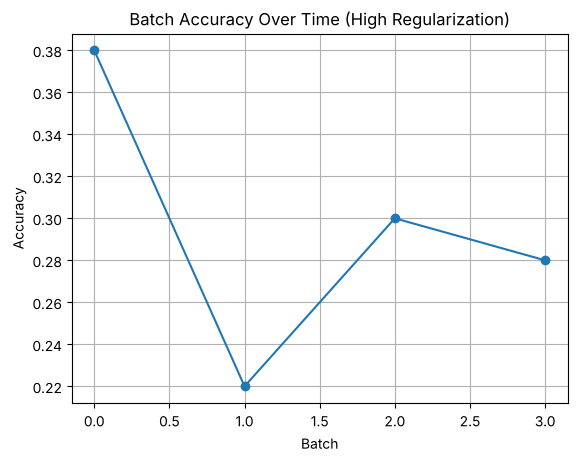

In [24]:
# Change the SGDClassifier hyperparameters to make the model less accurate
clf = SGDClassifier(loss="hinge", alpha=1.0, random_state=2024)  # Use SVM loss and strong regularization
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
batch_scores = []
for Xb, yb in zip(stream_batches, stream_labels):
    acc = np.mean(clf.predict(Xb) == yb)
    batch_scores.append(acc)

# Plot batch accuracy
plt.plot(batch_scores, marker='o')
plt.xlabel("Batch")
plt.ylabel("Accuracy")
plt.title("Batch Accuracy Over Time (High Regularization)")
plt.grid(True)
plt.show()

In [25]:
print('Akurasi per batch (model teregularisasi kuat):', np.round(batch_scores, 3))
print('Akurasi pada data latih awal                 : %.3f' % clf.score(X_train, y_train))
print('Norma bobot model                            : %.4f' % np.linalg.norm(clf.coef_))

Akurasi per batch (model teregularisasi kuat): [0.38 0.22 0.3  0.28]
Akurasi pada data latih awal                 : 0.902
Norma bobot model                            : 0.5604


**Interpretasi.** Latihan ini dimaksudkan untuk menunjukkan model yang "kurang akurat" lewat regularisasi kuat. Hasilnya lebih bernuansa:
- Bobot model memang sangat kecil (norma ≈ 0,56) karena `alpha=1.0` sangat besar untuk SGD.
- Namun akurasi pada data latih justru 0,902 — **tidak lebih buruk** daripada model Resep 4 (0,892). Pada data yang mudah dipisahkan, arah bobot lebih penting daripada besarnya; regularisasi kuat mengecilkan bobot tetapi arahnya tetap benar, sehingga label prediksi hampir tidak berubah.
- Akurasi per batch yang rendah (0,22–0,38) **bukan** akibat regularisasi, melainkan karena data stream-nya sama dengan Resep 4: masalah klasifikasi lain (`random_state=2025`).

Pelajaran: sebelum menyimpulkan penyebab penurunan performa di grafik monitoring, periksa dulu apakah masalahnya ada pada **model** atau pada **data** yang masuk.

### Latihan 3 — Mengotomatiskan pemeriksaan deployment dengan ambang validasi

In [26]:
# Load libraries
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Train and export model
X, y = make_classification(n_samples=300, n_features=10, random_state=2024)
model = LogisticRegression()
model.fit(X, y)
dump(model, "model_ci.joblib")

# Load and validate with test data
Xt, yt = make_classification(n_samples=100, n_features=10, random_state=2025)
model_prod = load("model_ci.joblib")
pred = model_prod.predict(Xt)
acc = accuracy_score(yt, pred)
print(f"Test Accuracy: {acc:.3f}")

# Conditionally approve deployment
if acc > 0.8:
    print("Deployment approved")
else:
    print("Deployment rejected")

Test Accuracy: 0.110
Deployment rejected


In [27]:
# Bandingkan dengan data uji dari distribusi yang SAMA (random_state sama, sampel berbeda)
X_full, y_full = make_classification(n_samples=400, n_features=10, random_state=2024)
X_same, y_same = X_full[300:], y_full[300:]
print('Model yang sama, dilatih ulang pada 300 sampel pertama...')
m = LogisticRegression().fit(X_full[:300], y_full[:300])
print('Akurasi pada 100 sampel berikutnya dari distribusi yang sama: %.3f' % accuracy_score(y_same, m.predict(X_same)))

Model yang sama, dilatih ulang pada 300 sampel pertama...
Akurasi pada 100 sampel berikutnya dari distribusi yang sama: 0.850


**Interpretasi.** Gerbang deployment menolak model karena akurasi uji hanya **0,110** — jauh di bawah tebakan acak. Penyebabnya sama seperti Resep 4: data uji dibangkitkan dengan `random_state=2025`, yaitu masalah klasifikasi yang berbeda dari data latih (`random_state=2024`), dan hubungan fitur–labelnya kebetulan hampir terbalik.

Sel tambahan membuktikan bahwa modelnya sendiri tidak buruk: dengan konfigurasi yang sama, model yang diuji pada 100 sampel baru dari distribusi yang **sama** mencapai akurasi 0,850 dan akan lolos ambang 0,8. Jadi penolakan di atas adalah keputusan yang "benar" untuk data uji tersebut, tetapi data ujinya tidak mewakili data produksi. Sekali lagi: **kualitas gerbang CI ditentukan oleh kualitas data validasinya**.

## Kesimpulan Bab 13

- **Serialisasi:** gunakan `joblib` untuk model scikit-learn (efisien untuk array besar, mendukung kompresi). Pickle/joblib **tidak aman** untuk berkas dari sumber yang tidak dipercaya, dan hanya dijamin kompatibel dengan versi library yang sama — catat versinya. ONNX/skops adalah alternatif untuk portabilitas dan keamanan.
- **Simpan seluruh `Pipeline`**, bukan hanya model, agar preprocessing produksi identik dengan pelatihan.
- **Skalabilitas:** `n_jobs` untuk paralelisme; prediksi **batch** jauh lebih efisien daripada satu per satu; Dask untuk skala cluster.
- **Monitoring:** performa akan menurun karena data/concept drift. Pantau metrik per batch, evaluasi data baru **sebelum** dipakai untuk update, dan perbarui dengan `partial_fit` atau pelatihan ulang.
- **Tata kelola:** versi artefak + metadata otomatis (versi library, hash data, hyperparameter) + snapshot prediksi validasi.
- **CI/CD/CT:** gerbang kualitas otomatis harus memakai data validasi yang **representatif** dan terpisah dari data latih; data acak atau data latih membuat gerbang itu tidak bermakna.